In [1]:
import sys
PATH_TO_PREDICTOR_HOME = "../.."
sys.path.append(PATH_TO_PREDICTOR_HOME)

METHOD = "hmm_pomegranate"


In [2]:
import sys
PATH_TO_PREDICTOR_HOME = "../.."
sys.path.append(PATH_TO_PREDICTOR_HOME)

import numpy as np
import pandas as pd
from os import listdir
from os.path import isfile, join
from mhcnames import normalize_allele_name

METHOD = "hmm_pomegranate"


# 1. Read data

In [3]:
DATA_PATH = 'D:/Google Drive/Work/ITMO/data/length_dependent_hmm/per_length_per_kfold_split/' # windows
DATA_PATH_IMMUNOGENIC = 'D:/Google Drive/Work/ITMO/data/length_dependent_hmm/immunogenic/per_length_per_kfold_split/' # windows
# DATA_PATH = '/home/denklewer/Data/length_dependent_hmm/' #ubuntu
TARGET_PATH_TO_RESULTS = "experiment_results/"


In [4]:
from data_reading_methods import get_available_alleles, read_data

ALLELES = get_available_alleles(DATA_PATH)

per_allele_per_kfold_per_length_binders_train = read_data(DATA_PATH, ALLELES, "train", "binders")
per_allele_per_kfold_per_length_binders_test = read_data(DATA_PATH, ALLELES, "test", "binders")
per_allele_per_kfold_per_length_non_binders_train = read_data(DATA_PATH, ALLELES, "train", "nonbinders")
per_allele_per_kfold_per_length_non_binders_test = read_data(DATA_PATH, ALLELES, "test", "nonbinders")

per_allele_per_kfold_per_length_immunogenic_train = read_data(DATA_PATH_IMMUNOGENIC, ALLELES, "train", "immunogenic")
per_allele_per_kfold_per_length_immunogenic_test = read_data(DATA_PATH_IMMUNOGENIC, ALLELES, "test", "immunogenic")
per_allele_per_kfold_per_length_non_immunogenic_train = read_data(DATA_PATH_IMMUNOGENIC, ALLELES, "train", "nonimmunogenic")
per_allele_per_kfold_per_length_non_immunogenic_test = read_data(DATA_PATH_IMMUNOGENIC, ALLELES, "test", "nonimmunogenic")

ALLELES

['HLA-A*02:01']

# 2. Read models

In [5]:
from hmm_logic_methods import load_model
total_splits = len(per_allele_per_kfold_per_length_binders_train[ALLELES[0]])
RUNS = 3



BAUM_WELCH_MODELS_15 = [f"{i}_run-8-15-st-baum-welch-alg-None-batches-1-batch_size-None-init_batch_size-0.0-lr-0.0-edge_inertia-0.0-distribution_inertia-0.0-emission_pseudocount-0.0-transition_pseudocount-30-min_iters-False-use_pseudocount" for i in range(RUNS)]

BAUM_WELCH_MODELS = [f"{i}_run-8-12-st-baum-welch-alg-None-batches-1-batch_size-None-init_batch_size-0.0-lr-0.0-edge_inertia-0.0-distribution_inertia-0.0-emission_pseudocount-0.0-transition_pseudocount-30-min_iters-False-use_pseudocount" for i in range(RUNS)]


MODEL_PREFIX_TO_READ =BAUM_WELCH_MODELS +  BAUM_WELCH_MODELS_15


per_name_model = dict()
for allele_name in ALLELES:
    target_allele_name = allele_name.replace('-', '_').replace('*', '_').replace(':', '_')
    for model_to_read in MODEL_PREFIX_TO_READ:
            for split_num in range(total_splits):
                model_name = f"{model_to_read}_model-{target_allele_name}-{split_num}"
                model = load_model(TARGET_PATH_TO_RESULTS, model_name)
                per_name_model[model_name] = model
                # print(model_name)

FileNotFoundError: [Errno 2] No such file or directory: 'experiment_results/0_run-8-12-st-baum-welch-alg-None-batches-1-batch_size-None-init_batch_size-0.0-lr-0.0-edge_inertia-0.0-distribution_inertia-0.0-emission_pseudocount-0.0-transition_pseudocount-30-min_iters-False-use_pseudocount_model-HLA_A_02_01-0//model.json'

# 1. Read data

In [ ]:
DATA_PATH = 'D:/Google Drive/Work/ITMO/data/length_dependent_hmm/per_length_per_kfold_split/' # windows
# DATA_PATH = '/home/denklewer/Data/length_dependent_hmm/' #ubuntu
TARGET_PATH_TO_RESULTS = "experiment_results/"


In [ ]:
from data_reading_methods import get_available_alleles, read_data

ALLELES = get_available_alleles(DATA_PATH)

per_allele_per_kfold_per_length_binders_train = read_data(DATA_PATH, ALLELES, "train", "binders")
per_allele_per_kfold_per_length_binders_test = read_data(DATA_PATH, ALLELES, "test", "binders")
per_allele_per_kfold_per_length_non_binders_train = read_data(DATA_PATH, ALLELES, "train", "nonbinders")
per_allele_per_kfold_per_length_non_binders_test = read_data(DATA_PATH, ALLELES, "test", "nonbinders")

ALLELES

# 3. Training

In [ ]:
from hmm_logic_methods import train_model, save_model, add_more_states_and_reset_transitions

## 3.1 from 8 to 9-mer
### 3.1.1 Add several states to existing models

In [ ]:
ADD_STATES_NUM = 5
base_model_prefix = "8-12-st"
new_state_prefix = "s9"
TARGET_LENGTHS = [8,9]
new_probs = "fair"
lengths_string = "-".join([str(length) for length in TARGET_LENGTHS])
freeze = "frozen"
assert freeze in ["frozen", "notfrozen"]
new_model_prefix = f"{lengths_string}-mer-of-{base_model_prefix}-{freeze}-{new_probs}"


per_allele_per_run_per_split_prepared_models = dict()

models_params_string= "baum-welch-alg-None-batches-1-batch_size-None-init_batch_size-0.0-lr-0.0-edge_inertia-0.0-distribution_inertia-0.0-emission_pseudocount-0.0-transition_pseudocount-30-min_iters-False-use_pseudocount"


for allele_name in ALLELES:
    per_allele_per_run_per_split_prepared_models[allele_name] = dict()
    for run_num in range(RUNS):
        print(f"Run {run_num}")
        new_model_prefix = f"{run_num}_run-{new_model_prefix}"
        per_allele_per_run_per_split_prepared_models[allele_name][run_num] = dict()
        for split_num, per_length_data in per_allele_per_kfold_per_length_binders_train[allele_name].items():
            print(f"Split {split_num}")
            target_allele_name = allele_name.replace('-', '_').replace('*', '_').replace(':', '_')
            base_model_name = f"{run_num}_run-{base_model_prefix}-{models_params_string}_model-{target_allele_name}-{split_num}"

            base_model = per_name_model[base_model_name]
            new_model = add_more_states_and_reset_transitions(base_model,
                                                              ADD_STATES_NUM,
                                                              new_state_prefix,
                                                              f"{new_model_prefix}_model-{target_allele_name}-{split_num}",
                                                              new_probs=new_probs)
            per_allele_per_run_per_split_prepared_models[allele_name][run_num][split_num] = new_model
            if freeze == "frozen":
                print("Freezing the distribution for new states")
                for state in new_model.states:
                    if not state.name.startswith(new_state_prefix) and state is not new_model.start and state is not new_model.end:
                        state.distribution.freeze()
                        print(f"freezed {state.name}")


### 3.1.2. Train prepared models

In [6]:
per_allele_per_run_per_split_new_models = dict()
per_allele_per_run_per_split_new_histories = dict()
for allele_name in ALLELES:
    per_allele_per_run_per_split_new_models[allele_name] = dict()
    per_allele_per_run_per_split_new_histories[allele_name] = dict()
    for run_num in range(RUNS):
        per_kfold_per_length_data =  per_allele_per_kfold_per_length_binders_train[allele_name]
        models, histories = train_model(allele_name,
                                        per_kfold_per_length_data,
                                        TARGET_LENGTHS,
                                        multiple_check_input=False,
                                        verbose=True,
                                        prepared_models=per_allele_per_run_per_split_prepared_models[allele_name][run_num])
        per_allele_per_run_per_split_new_models[allele_name][run_num] = models
        per_allele_per_run_per_split_new_histories[allele_name][run_num] = histories

NameError: name 'train_model' is not defined

In [22]:
for allele_name in ALLELES:
    for run_num in range(RUNS):
        for split_num, model in per_allele_per_run_per_split_new_models[allele_name][run_num].items():
            history = per_allele_per_run_per_split_new_histories[allele_name][run_num][split_num]
            save_model(model,history, TARGET_PATH_TO_RESULTS)

## Freeze distribution for 8-mers

In [47]:
for state in model_9.states:
    if state.name.startswith("s8"):
        state.distribution.freeze()
        print(f"freezed {state.name}")


freezed s8_0
freezed s8_1
freezed s8_10
freezed s8_11
freezed s8_2
freezed s8_3
freezed s8_4
freezed s8_5
freezed s8_6
freezed s8_7
freezed s8_8
freezed s8_9


## Train 9-mers

In [48]:
TARGET_LENGTH = 9
binders_array = per_allele_per_length_binders_train[allele_name][TARGET_LENGTH][:6000]
non_binders_array =  per_allele_per_length_non_binders_train[allele_name][TARGET_LENGTH][:6000]

len(binders_array)

6000

In [49]:
%%time
for df in per_allele_train_df.values():
    print("max length {}".format(max(df.peptide.str.len())))
kf = KFold(n_splits=5)
llCutoff = 0.00005
i = 0
for train_indexes_b, test_indexes_b in kf.split(binders_array):
    i = i + 1
    print("split {}".format(i))
    print("train/test {}/{}".format(len(train_indexes_b), len(test_indexes_b)))

    current_train_b = binders_array[train_indexes_b]
    current_test_b = binders_array[test_indexes_b]
    current_train_nb = non_binders_array
    current_test_nb = non_binders_array

    df_binders = pd.DataFrame({"peptide": current_train_b})
    df_non_binders = pd.DataFrame({"peptide": current_train_nb})

    sample_X = np.array([[char for char in item] for item in current_train_b])

    model_9, history = model_9.fit(sample_X,
                                   stop_threshold=5e-5,
                                   return_history=True,
                                   verbose=True,
                                   multiple_check_input=False
                                   )
    break

max length 43
split 1
train/test 4800/1200
[1] Improvement: 4110.696352291125	Time (s): 0.977
[2] Improvement: 943.6248241482535	Time (s): 1.028
[3] Improvement: 524.7906412711018	Time (s): 1.222
[4] Improvement: 378.83023411483737	Time (s): 0.987
[5] Improvement: 315.09699246447417	Time (s): 1.012
[6] Improvement: 290.09562133626605	Time (s): 0.953
[7] Improvement: 290.31671149061003	Time (s): 0.955
[8] Improvement: 310.34747186719324	Time (s): 0.966
[9] Improvement: 349.1008907835203	Time (s): 1.069
[10] Improvement: 412.11285580416734	Time (s): 0.994
[11] Improvement: 518.8930627297523	Time (s): 0.953
[12] Improvement: 717.7986674316344	Time (s): 1.016
[13] Improvement: 1114.7666785390466	Time (s): 0.961
[14] Improvement: 1880.999274197704	Time (s): 0.971
[15] Improvement: 2683.267387739528	Time (s): 0.991
[16] Improvement: 1672.3530639265373	Time (s): 1.05
[17] Improvement: 257.635213162881	Time (s): 0.956
[18] Improvement: 30.20645534124924	Time (s): 1.007
[19] Improvement: 13.103

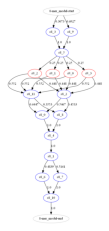

In [51]:
file = open("model_9_cropped_trained.png", 'w+')
model_9.plot(file=file, crop_zero=True, precision=4)

In [52]:
model_9.dense_transition_matrix()

array([[0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 1.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        ],
       [0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.48394319, 0.51605681,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        ],
       [0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 1.        ],
       [0.64471461, 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.35528539, 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        ],
    

In [53]:
[(i, state.name) for i, state in enumerate(model_9.states)]

[(0, 's8_0'),
 (1, 's8_1'),
 (2, 's8_10'),
 (3, 's8_11'),
 (4, 's8_2'),
 (5, 's8_3'),
 (6, 's8_4'),
 (7, 's8_5'),
 (8, 's8_6'),
 (9, 's8_7'),
 (10, 's8_8'),
 (11, 's8_9'),
 (12, 's9_0'),
 (13, 's9_1'),
 (14, 's9_2'),
 (15, 's9_3'),
 (16, '8-mer_model-start'),
 (17, '8-mer_model-end')]

In [54]:
sequence = list(peptide_train_b)
logp, path = model_8.viterbi(sequence)

print("Sequence: '{}'  -- Log Probability: {} -- Path: {}".format(''.join( sequence ), logp, " ".join( state.name for idx, state in path[1:-1] ) ))

logp, path = model_8.maximum_a_posteriori(sequence)

print("Sequence: '{}'  -- Log Probability: {} -- Path: {}".format(''.join( sequence ), logp, " ".join( state.name for idx, state in path ) ))

Sequence: 'QLIAGQSA'  -- Log Probability: -23.538503014627594 -- Path: s8_9 s8_5 s8_11 s8_0 s8_4 s8_1 s8_6 s8_10
Sequence: 'QLIAGQSA'  -- Log Probability: -1.2638008068964126 -- Path: s8_9 s8_5 s8_11 s8_0 s8_4 s8_1 s8_6 s8_10


In [55]:
sequence

['Q', 'L', 'I', 'A', 'G', 'Q', 'S', 'A']

In [56]:
model_9.viterbi(sequence)

(-inf, None)

In [57]:
sequence = list(binders_array[0])
logp, path = model_9.viterbi(sequence)

print("Sequence: '{}'  -- Log Probability: {} -- Path: {}".format(''.join( sequence ), logp, " ".join( state.name for idx, state in path[1:-1] ) ))

logp, path = model_9.maximum_a_posteriori(sequence)

print("Sequence: '{}'  -- Log Probability: {} -- Path: {}".format(''.join( sequence ), logp, " ".join( state.name for idx, state in path ) ))

Sequence: 'FMYSDFHFI'  -- Log Probability: -29.143669025688645 -- Path: s8_9 s8_5 s9_0 s8_11 s8_0 s8_4 s8_1 s8_6 s8_10
Sequence: 'FMYSDFHFI'  -- Log Probability: -2.372818913792681 -- Path: s8_9 s8_5 s9_0 s8_11 s8_0 s8_4 s8_1 s8_6 s8_10


## 8-mer then 9-mer

In [58]:
model_8_9 = add_more_states_and_reset_transitions(model_8, ADD_STATES_NUM)

Initial length 14
num states to add 4
After length 18
 N is  16
sum from start 2.0
8-mer_model : s8_0 summed to 2.0, normalized to 1.0
8-mer_model : s8_1 summed to 2.0, normalized to 1.0
8-mer_model : s8_10 summed to 2.0, normalized to 1.0
8-mer_model : s8_11 summed to 2.0, normalized to 1.0
8-mer_model : s8_2 summed to 2.0, normalized to 1.0
8-mer_model : s8_3 summed to 2.0, normalized to 1.0
8-mer_model : s8_4 summed to 2.0, normalized to 1.0
8-mer_model : s8_5 summed to 2.0, normalized to 1.0
8-mer_model : s8_6 summed to 2.0, normalized to 1.0
8-mer_model : s8_7 summed to 2.0, normalized to 1.0
8-mer_model : s8_8 summed to 2.0, normalized to 1.0
8-mer_model : s8_9 summed to 2.0, normalized to 1.0
8-mer_model : 8-mer_model-start summed to 2.0, normalized to 1.0
8-mer_model : s9_0 summed to 17.0, normalized to 1.0
8-mer_model : s9_1 summed to 17.0, normalized to 1.0
8-mer_model : s9_2 summed to 17.0, normalized to 1.0
8-mer_model : s9_3 summed to 17.0, normalized to 1.0


In [59]:
for state in model_8_9.states:
    if state.name.startswith("s8"):
        state.distribution.freeze()
        print(f"freezed {state.name}")

freezed s8_0
freezed s8_1
freezed s8_10
freezed s8_11
freezed s8_2
freezed s8_3
freezed s8_4
freezed s8_5
freezed s8_6
freezed s8_7
freezed s8_8
freezed s8_9


In [60]:
binders_array = np.concatenate(
    (per_allele_per_length_binders_train[allele_name][8][:6000] , per_allele_per_length_binders_train[allele_name][9][:6000] ))
non_binders_array =  np.concatenate(( per_allele_per_length_non_binders_train[allele_name][8][:6000], per_allele_per_length_binders_train[allele_name][9][:6000] ))


len(binders_array)

8991

In [61]:
%%time
for df in per_allele_train_df.values():
    print("max length {}".format(max(df.peptide.str.len())))
kf = KFold(n_splits=5)
llCutoff = 0.00005
i = 0
for train_indexes_b, test_indexes_b in kf.split(binders_array):
    i = i + 1
    print("split {}".format(i))
    print("train/test {}/{}".format(len(train_indexes_b), len(test_indexes_b)))

    current_train_b = binders_array[train_indexes_b]
    current_test_b = binders_array[test_indexes_b]
    current_train_nb = non_binders_array
    current_test_nb = non_binders_array

    df_binders = pd.DataFrame({"peptide": current_train_b})
    df_non_binders = pd.DataFrame({"peptide": current_train_nb})

    sample_X = np.array([[char for char in item] for item in current_train_b])

    model_8_9, history = model_8_9.fit(sample_X,
                                   stop_threshold=5e-5,
                                   return_history=True,
                                   verbose=True,
                                   multiple_check_input=False
                                   )
    break

max length 43
split 1
train/test 7192/1799


<timed exec>:19: VisibleDeprecationWarning: Creating an ndarray from ragged nested sequences (which is a list-or-tuple of lists-or-tuples-or ndarrays with different lengths or shapes) is deprecated. If you meant to do this, you must specify 'dtype=object' when creating the ndarray.


[1] Improvement: 5881.933832133509	Time (s): 1.403
[2] Improvement: 1656.3743325662508	Time (s): 1.41
[3] Improvement: 1135.6239932320022	Time (s): 1.461
[4] Improvement: 890.3697266581003	Time (s): 1.414
[5] Improvement: 721.65912627129	Time (s): 1.488
[6] Improvement: 625.6633716088836	Time (s): 1.403
[7] Improvement: 601.4663504030905	Time (s): 1.461
[8] Improvement: 637.5616442964529	Time (s): 1.41
[9] Improvement: 740.4523721924634	Time (s): 1.492
[10] Improvement: 963.0449024143163	Time (s): 1.429
[11] Improvement: 1438.7796153105737	Time (s): 1.465
[12] Improvement: 2308.9852479069377	Time (s): 1.418
[13] Improvement: 2811.4532177765213	Time (s): 1.447
[14] Improvement: 1433.275588150398	Time (s): 1.472
[15] Improvement: 235.8344897054776	Time (s): 1.56
[16] Improvement: 30.011116944166133	Time (s): 1.6
[17] Improvement: 13.308435182232643	Time (s): 1.577
[18] Improvement: 8.906637358566513	Time (s): 1.463
[19] Improvement: 6.864334062905982	Time (s): 1.432
[20] Improvement: 5.7

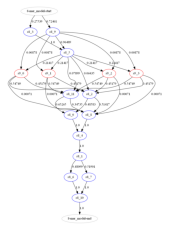

In [62]:
file = open("model_8_9_cropped_trained_freeze.png", 'w+')
model_8_9.plot(file=file, crop_zero=True, precision=5)

In [197]:
sequence = list(peptide_train_b)
logp, path = model_8_9.viterbi(sequence)

print("Sequence: '{}'  -- Log Probability: {} -- Path: {}".format(''.join( sequence ), logp, " ".join( state.name for idx, state in path[1:-1] ) ))

logp, path = model_8_9.maximum_a_posteriori(sequence)

print("Sequence: '{}'  -- Log Probability: {} -- Path: {}".format(''.join( sequence ), logp, " ".join( state.name for idx, state in path ) ))

Sequence: 'QLIAGQSA'  -- Log Probability: -25.933515401191837 -- Path: s8_7 s8_2 s8_9 s8_6 s8_8 s8_5 s8_3 s8_1
Sequence: 'QLIAGQSA'  -- Log Probability: -2.637277017204376 -- Path: s8_7 s8_2 s8_9 s8_4 s9_0 s8_0 s8_10 s8_1


In [204]:
sequence = list(binders_array[-666])
logp, path = model_8_9.viterbi(sequence)

print("Sequence: '{}'  -- Log Probability: {} -- Path: {}".format(''.join( sequence ), logp, " ".join( state.name for idx, state in path[1:-1] ) ))

logp, path = model_8_9.maximum_a_posteriori(sequence)

print("Sequence: '{}'  -- Log Probability: {} -- Path: {}".format(''.join( sequence ), logp, " ".join( state.name for idx, state in path ) ))

Sequence: 'LLAVAVYAV'  -- Log Probability: -22.480943662056454 -- Path: s8_7 s8_2 s8_9 s8_6 s9_0 s8_8 s8_5 s8_3 s8_1
Sequence: 'LLAVAVYAV'  -- Log Probability: -2.048690262934855 -- Path: s8_7 s8_2 s8_9 s8_6 s9_0 s8_8 s8_5 s8_3 s8_1


Same visualization

In [66]:
model_9.name = '9-mer_model'
model_8_9.name = '8-9-mer_model'

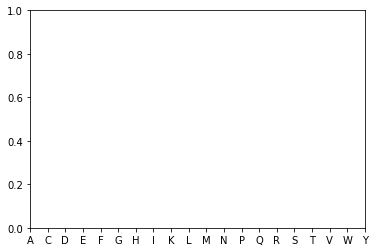

In [70]:
plotDistributionsForStates(model_9)
gr, name_to_level = convert_graph_to_good_format(model_9)

In [71]:
nt = make_pyviz_graph(model_9, gr)